# Tufa Labs ARC3 submission

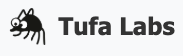

This notebook executes the ARC-AGI-3 solver written by the Tufa Labs team; in alphabetical order: Harold Bessis, Jeroen Cottaar, Isaiah Pressman, Andries Smit, Michal Tesnar, and Stefano Viel.

You will only find infrastructure and diagnostics in this notebook; the actual solver code is in an attached dataset. See our writeup on the competition forum to learn more about that the solver actually does.

It installs the ARC runtime from the competition wheelhouse, makes the bundled source
snapshot importable, runs any solver setup commands, loads the pickled benchmark, plays the
competition games, and writes results to `/kaggle/working`. Diagnostics are minimised during
a real competition rerun (`KAGGLE_IS_COMPETITION_RERUN`) and kept full otherwise.

## 1. Environment and submission mode

Detect whether this is a real competition rerun (which minimises diagnostics), set the
framework's environment flags, and put the CUDA libraries on the linker path.

In [ ]:
import json
import os
import pickle
import subprocess
import sys
import sysconfig
import time
from datetime import datetime, timedelta
from pathlib import Path
from urllib.request import urlopen

# True only inside a real competition rerun; switches diagnostics + soft deadline.
TRUE_SUBMISSION = os.environ.get("KAGGLE_IS_COMPETITION_RERUN", "").strip().lower() in {"1", "true"}
NOTEBOOK_START_EPOCH = time.time()

# Non-interactive matplotlib backend: diagnostics render plots with no display attached.
os.environ["MPLBACKEND"] = "Agg"
# Marks the run as a (real or emulated) submission so the framework + solver can adjust.
os.environ["TAAF_RUN_AS_SUBMISSION"] = "1" if TRUE_SUBMISSION else "0"
# In submission, disable the periodic JSON/HTML diagnostics writes and per-frame logging.
os.environ["TAAF_MINIMAL_DIAGNOSTICS"] = "1" if TRUE_SUBMISSION else "0"
# Pin arc_agi's cached level_reset_only before its client is built (RESET keeps the level).
os.environ["ONLY_RESET_LEVELS"] = "true"

# Prepend the CUDA toolkit to the linker path (it is off it on Kaggle GPU images) so the
# solver's GPU libraries (e.g. vllm / torch) can link against libcuda.
cuda_library_path = "/usr/local/nvidia/lib64"
os.environ["LIBRARY_PATH"] = os.pathsep.join(
    entry for entry in [cuda_library_path, *os.environ.get("LIBRARY_PATH", "").split(os.pathsep)] if entry
)

# Everything the run produces is written here.
WORKING_DIR = Path("/kaggle/working")
WORKING_DIR.mkdir(parents=True, exist_ok=True)
print(f"taaf.kaggle: TRUE_SUBMISSION={TRUE_SUBMISSION}")

## 2. Install the ARC runtime

Install `arc-agi` from the offline competition wheelhouse (the Kaggle submission environment
has no internet).

In [ ]:
# Install the ARC runtime from the bundled competition wheels.
# Quiet: stdout is discarded; stderr (and a non-zero exit) still surface real failures.
subprocess.check_call(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--no-index",
        "--no-warn-conflicts",
        "--disable-pip-version-check",
        "--find-links",
        "/kaggle/input/competitions/arc-prize-2026-arc-agi-3/arc_agi_3_wheels",
        "arc-agi",
    ],
    stdout=subprocess.DEVNULL,
)

## 3. Locate the source bundle

Find the uploaded TAAF source dataset by its marker file, and record where Kaggle mounted
every attached input so setup commands and the solver can find them.

In [ ]:
# Kaggle inputs attached to this notebook, plus bookkeeping paths used below.
DATASET_SOURCES = ["jeroencottaar/taaf-kaggle-source-share", "driessmit1/arc3-vllm-h100-wheelhouse-v3", "driessmit1/vrfai-qwen3-6-27b-fp8-hf-snapshot"]
KERNEL_SOURCES = []
DATASET_BUNDLE_MARKER = "taaf-kaggle-bundle.json"
SETUP_ENV_PATH = WORKING_DIR / "taaf_setup_env.json"


# Locate the source dataset by its marker file rather than a fixed mount path.
def _find_bundle_dir() -> Path:
    for marker in Path("/kaggle/input").rglob(DATASET_BUNDLE_MARKER):
        return marker.parent
    raise RuntimeError("TAAF source bundle not found under /kaggle/input.")


# Kaggle mounts a dataset at /kaggle/input/<slug> or /kaggle/input/datasets/<owner>/<slug>
# (depending on owner / slug collisions), so probe both and use whichever exists. Utility
# scripts mount under /kaggle/usr/lib/notebooks/<owner>/<slug>.
def _dataset_mount_candidates(ref: str) -> list[Path]:
    owner, slug = ref.split("/", 1)
    return [Path("/kaggle/input") / slug, Path("/kaggle/input/datasets") / owner / slug]


def _kernel_mount_candidates(ref: str) -> list[Path]:
    owner, slug = ref.split("/", 1)
    return [Path("/kaggle/usr/lib/notebooks") / owner / slug]


def _first_existing(candidates: list[Path]) -> Path | None:
    return next((c for c in candidates if c.exists()), None)


BUNDLE_DIR = _find_bundle_dir()
print(f"taaf.kaggle: source bundle = {BUNDLE_DIR}")

# Map each attached input to where Kaggle actually mounted it (the source bundle is index 0).
kaggle_input_paths: dict[str, str] = {}
for i, ref in enumerate(DATASET_SOURCES):
    candidates = _dataset_mount_candidates(ref)
    resolved = BUNDLE_DIR if i == 0 else _first_existing(candidates)
    kaggle_input_paths[ref] = str(resolved or candidates[0])
for ref in KERNEL_SOURCES:
    candidates = _kernel_mount_candidates(ref)
    kaggle_input_paths[ref] = str(_first_existing(candidates) or candidates[0])

# Published to setup commands and the solver via the environment:
setup_env = {
    # JSON {ref: mount_path} so they can locate every attached dataset / utility script.
    "TAAF_KAGGLE_INPUT_PATHS": json.dumps(kaggle_input_paths, sort_keys=True),
    # The attached dataset refs in order (index 0 is this source bundle).
    "TAAF_KAGGLE_DATASET_SOURCES": json.dumps(DATASET_SOURCES),
    # The attached utility-script / kernel refs.
    "TAAF_KAGGLE_KERNEL_SOURCES": json.dumps(KERNEL_SOURCES),
}
os.environ.update(setup_env)
SETUP_ENV_PATH.write_text(json.dumps(setup_env, indent=2, sort_keys=True) + "\n")
print(f"taaf.kaggle: input paths = {setup_env['TAAF_KAGGLE_INPUT_PATHS']}")

## 4. Import the bundled source and run solver setup

Put the snapshotted repositories on the path (this process and any child processes), then run
the solver's setup commands — installing wheels, fetching model weights, and so on.

In [ ]:
# Each bundled repo exposes its importable tree at <repo>/src or <repo>.
def _source_path_entries(bundle_dir: Path) -> list:
    entries = []
    for repo in sorted((bundle_dir / "src").iterdir(), reverse=True):
        for candidate in (repo / "src", repo):
            if candidate.is_dir():
                entries.append(candidate)
    return entries


# Environment handed to each setup command (paths + any keys it has persisted).
def _command_env() -> dict:
    env = os.environ.copy()
    # "$PYTHON" in a command resolves to this notebook's interpreter.
    env["PYTHON"] = sys.executable
    # Absolute path to the mounted source bundle.
    env["TAAF_KAGGLE_BUNDLE_DIR"] = str(BUNDLE_DIR)
    # The writable /kaggle/working directory.
    env["TAAF_KAGGLE_WORKING_DIR"] = str(WORKING_DIR)
    # A command writes a JSON object here to persist env keys to later commands + the run.
    env["TAAF_KAGGLE_SETUP_ENV"] = str(SETUP_ENV_PATH)
    env.update({str(k): str(v) for k, v in json.loads(SETUP_ENV_PATH.read_text()).items()})
    return env


# Make the bundled repos importable here (sys.path) and in child processes (.pth).
source_entries = _source_path_entries(BUNDLE_DIR)
for entry in source_entries:
    sys.path.insert(0, str(entry))
pth_path = Path(sysconfig.get_paths()["purelib"]) / "taaf_kaggle_sources.pth"
pth_path.write_text("".join(f"{entry}\n" for entry in source_entries))
print(f"taaf.kaggle: wrote {pth_path} ({len(source_entries)} source roots)")

# Solver setup commands (wheels, vLLM server startup, ...) run before the benchmark loads.
env = _command_env()
for command in json.loads((BUNDLE_DIR / "setup_commands.json").read_text()):
    print(f"taaf.kaggle: setup command: {command}", flush=True)
    subprocess.run(command, shell=True, check=True, cwd=WORKING_DIR, env=env)
    # Re-read in case the command persisted new env keys.
    env = _command_env()
    os.environ.update(env)

# Honour any PYTHONPATH a setup command exported.
for entry in reversed([e for e in os.environ.get("PYTHONPATH", "").split(os.pathsep) if e]):
    if entry not in sys.path:
        sys.path.insert(0, entry)

## 4b. Cartograph: write the package

Cartograph adds a persistent `world_model.py`, an exact-replay verifier and a verification gate to the Duck harness **without editing the harness**: `CartographToolAgent` subclasses Duck's `ToolAgent`. Everything is local and offline (no external API). The cells below write the package to disk so this notebook is self-contained; source is in the Cartograph repository.


In [ ]:
import sys
from pathlib import Path
Path('/kaggle/working/cartograph_src/cartograph').mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(Path('/kaggle/working/cartograph_src/cartograph').parent))


In [ ]:
%%writefile /kaggle/working/cartograph_src/cartograph/__init__.py
"""Cartograph: verified executable world models for a Duck-style harness.

Harness-independent pieces (importable without the Duck harness installed):
  - cartograph.verifier   exact-replay verifier
  - cartograph.workspace  persistent world_model.py + verification log

Harness-dependent piece (needs the Duck harness on sys.path):
  - cartograph.agent      CartographToolAgent, a subclass of Duck's ToolAgent
"""


In [ ]:
%%writefile /kaggle/working/cartograph_src/cartograph/verifier.py
"""Exact-replay verifier for an agent-written world model.

Contract of ``world_model.py`` (written by the agent):

    def transition(state, action) -> next_state

  * ``state``  : tuple of row strings, one letter per cell. These are exactly the
                 characters of ``Frame.ascii`` in the Duck harness, i.e. what the
                 agent already sees (the raw numeric grid is hidden from it).
  * ``action`` : the action string as recorded in the Duck history, e.g. ``"UP"``,
                 ``"SPACE"``, ``"MOUSE(row=3, col=4)"``.
  * returns    : the next state in the same representation (tuple/list of str).

Verification rule (what "verified" means):

    Start from the initial observed state (history[0]). Replay the ENTIRE recorded
    history through ``transition``. The model is verified only if, for every
    replayed transition, the predicted next state equals the observed next frame
    cell for cell, AND at least ``min_checked`` transitions were actually checked.

Design decision (documented deviation, see ``anchor`` below): two kinds of recorded
transitions are *discontinuities of the environment*, not dynamics a per-level
transition function can be expected to predict: a level change (the next level's
layout is new information) and ``RESET`` (restores a level start that the model has
no state to know). Unless ``strict=True``, the replay re-anchors on the observed
frame at those steps instead of checking them. They are counted separately
(``n_anchored``) and reported, never silently counted as passes. ``strict=True``
checks every transition, anchors included.

The model code is untrusted LLM output, so it runs in a child process
(``python -I -S``) with resource limits, a wall-clock timeout, a restricted builtins
table and an import allowlist. The allowlist deliberately equals the Duck python
tool's, so a model that verifies here also runs inside the Duck sandbox (this is
what makes it usable for planning). This is a consistency measure, not a hardened
security boundary - the same is true of the harness sandbox it mirrors.
"""
from __future__ import annotations

import hashlib
import json
import os
import signal
import subprocess
import sys
import textwrap
import time
from dataclasses import asdict, dataclass, field
from typing import Any, Sequence

# One recorded step: (action string, rows of letters, level number).
# history[0] is the initial observation (its action is ignored).
HistoryItem = tuple[str, tuple[str, ...], int]

# MUST stay a subset of the Duck sandbox's SAFE_MODULES / SAFE_BUILTINS
# (inference/agent/python_tool_sandbox.py). tests/test_agent_gating.py checks this
# against the real harness whenever the harness is importable.
SAFE_MODULES = (
    "bisect", "collections", "copy", "fractions", "functools", "heapq", "itertools",
    "json", "math", "operator", "random", "re", "statistics", "string",
)
SAFE_BUILTINS = (
    "abs", "all", "any", "ascii", "bin", "bool", "bytearray", "bytes", "callable", "chr",
    "complex", "dict", "dir", "divmod", "enumerate", "Exception", "filter", "float",
    "format", "frozenset", "getattr", "hasattr", "hash", "hex", "int", "isinstance",
    "issubclass", "iter", "len", "list", "map", "max", "min", "next", "oct", "ord", "pow",
    "print", "range", "repr", "reversed", "round", "set", "slice", "sorted", "str", "sum",
    "tuple", "TypeError", "type", "ValueError", "RuntimeError", "zip",
)

MAX_DIFF_SAMPLES = 5


@dataclass
class VerificationResult:
    verified: bool
    n_transitions: int = 0      # transitions present in the history (len(history) - 1)
    n_checked: int = 0          # transitions predicted by the model and compared
    n_anchored: int = 0         # level-change / RESET steps re-anchored (not checked)
    strict: bool = False
    first_mismatch: dict[str, Any] | None = None   # {index, action, kind, n_diff, diffs}
    error: str | None = None    # load/runtime/timeout/format problem, if any
    reason: str = ""            # one-line human summary
    model_sha256: str = ""
    elapsed_s: float = 0.0

    def to_dict(self) -> dict[str, Any]:
        return asdict(self)


# --- child process --------------------------------------------------------------
# Reads one JSON line {source, history, strict, timeout_s}; writes one JSON line.
_CHILD = textwrap.dedent(
    r"""
    import builtins, io, json, sys

    try:
        import resource
    except ImportError:
        resource = None

    REAL_STDOUT = sys.stdout
    req = json.loads(sys.stdin.readline())
    if resource is not None:
        cpu = max(1, int(req["timeout_s"])) + 1
        for lim, val in ((resource.RLIMIT_CPU, cpu), (resource.RLIMIT_FSIZE, 1_000_000),
                         (resource.RLIMIT_NOFILE, 32), (resource.RLIMIT_AS, 2 * 1024 ** 3)):
            try:
                resource.setrlimit(lim, (val, val))
            except (OSError, ValueError):
                pass

    SAFE_MODULES = set(req["safe_modules"])

    def _safe_import(name, globals=None, locals=None, fromlist=(), level=0):
        if str(name or "").split(".", 1)[0] not in SAFE_MODULES:
            raise ImportError("Module '%s' is not allowed in the world-model sandbox." % name)
        return builtins.__import__(name, globals, locals, fromlist, level)

    safe = {n: getattr(builtins, n) for n in req["safe_builtins"]}
    safe["__import__"] = _safe_import
    ns = {"__builtins__": safe, "__name__": "world_model"}

    def emit(**kw):
        REAL_STDOUT.write(json.dumps(kw) + "\n")
        REAL_STDOUT.flush()

    def short(e):
        return ("%s: %s" % (type(e).__name__, e))[:300]

    sys.stdout = io.StringIO()   # a model that print()s must not corrupt the protocol
    try:
        exec(compile(req["source"], "world_model.py", "exec"), ns)
    except Exception as e:
        emit(error="load failed: " + short(e)); raise SystemExit
    fn = ns.get("transition")
    if not callable(fn):
        emit(error="world_model.py must define transition(state, action)"); raise SystemExit

    hist, strict = req["history"], req["strict"]
    state = tuple(hist[0][1])
    checked = anchored = 0
    for i in range(1, len(hist)):
        action, obs_rows, level = hist[i][0], tuple(hist[i][1]), hist[i][2]
        if (not strict) and (level != hist[i - 1][2] or action.strip().upper() == "RESET"):
            state = obs_rows; anchored += 1
            continue
        try:
            out = fn(state, action)
        except Exception as e:
            emit(checked=checked, anchored=anchored, error="transition raised at step %d (%s): %s" % (i, action, short(e)),
                 mismatch={"index": i, "action": action, "kind": "exception"}); raise SystemExit
        if not (isinstance(out, (list, tuple)) and all(type(r) is str for r in out)):
            emit(checked=checked, anchored=anchored,
                 mismatch={"index": i, "action": action, "kind": "bad_return_type",
                           "got_type": type(out).__name__}); raise SystemExit
        out = tuple(out)
        checked += 1
        if out != obs_rows:
            m = {"index": i, "action": action}
            if len(out) != len(obs_rows) or any(len(a) != len(b) for a, b in zip(out, obs_rows)):
                m.update(kind="shape", expected="%dx%d" % (len(obs_rows), len(obs_rows[0]) if obs_rows else 0),
                         got="%dx%d" % (len(out), len(out[0]) if out else 0))
            else:
                diffs = [(r, c, obs_rows[r][c], out[r][c]) for r in range(len(out))
                         for c in range(len(out[r])) if out[r][c] != obs_rows[r][c]]
                m.update(kind="cells", n_diff=len(diffs), diffs=diffs[:req["max_diffs"]])
            emit(checked=checked, anchored=anchored, mismatch=m); raise SystemExit
        state = obs_rows   # equal to out; use the observed object
    emit(checked=checked, anchored=anchored, mismatch=None)
    """
)


def _kill_group(proc: subprocess.Popen) -> None:
    try:
        os.killpg(proc.pid, signal.SIGKILL)
    except OSError:
        try:
            proc.kill()
        except OSError:
            pass


def verify_exact_replay(
    source: str,
    history: Sequence[HistoryItem],
    *,
    strict: bool = False,
    min_checked: int = 1,
    timeout_s: float = 20.0,
) -> VerificationResult:
    """Replay ``history`` through the model in ``source``; see module docstring."""
    t0 = time.monotonic()
    sha = hashlib.sha256(source.encode("utf-8")).hexdigest()[:16]
    base = dict(
        n_transitions=max(0, len(history) - 1), strict=strict, model_sha256=sha,
    )

    def done(verified: bool, **kw: Any) -> VerificationResult:
        return VerificationResult(verified=verified, elapsed_s=round(time.monotonic() - t0, 4),
                                  **{**base, **kw})

    if not history:
        return done(False, error="empty history", reason="no history to replay")

    req = {
        "source": source,
        "history": [[a, list(rows), int(level)] for a, rows, level in history],
        "strict": strict,
        "timeout_s": timeout_s,
        "max_diffs": MAX_DIFF_SAMPLES,
        "safe_modules": list(SAFE_MODULES),
        "safe_builtins": list(SAFE_BUILTINS),
    }
    try:
        proc = subprocess.Popen(
            [sys.executable, "-I", "-S", "-c", _CHILD],
            stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=subprocess.PIPE,
            text=True, encoding="utf-8", start_new_session=True,
            env={"PYTHONIOENCODING": "utf-8", "PYTHONDONTWRITEBYTECODE": "1", "HOME": "/tmp"},
        )
    except OSError as exc:
        return done(False, error=f"verifier process could not start: {exc}", reason="verifier error")
    try:
        stdout, _ = proc.communicate(json.dumps(req), timeout=timeout_s)
    except subprocess.TimeoutExpired:
        _kill_group(proc)
        proc.communicate()
        return done(False, error=f"replay timed out after {timeout_s}s", reason="timeout")

    lines = [ln for ln in stdout.splitlines() if ln.strip()]
    try:
        msg = json.loads(lines[-1])
    except (IndexError, json.JSONDecodeError):
        return done(False, error="verifier child produced no result (crash, limit hit, or exit)",
                    reason="verifier error")

    checked, anchored = int(msg.get("checked", 0)), int(msg.get("anchored", 0))
    common = dict(n_checked=checked, n_anchored=anchored)
    if msg.get("error"):
        return done(False, error=msg["error"], first_mismatch=msg.get("mismatch"),
                    reason=msg["error"], **common)
    mismatch = msg.get("mismatch")
    if mismatch:
        what = mismatch.get("kind")
        n = mismatch.get("n_diff")
        return done(False, first_mismatch=mismatch, reason=(
            f"mismatch at step {mismatch['index']} ({mismatch['action']}): {what}"
            + (f", {n} cell(s) differ" if n is not None else "")), **common)
    if checked < min_checked:
        return done(False, reason=(f"vacuous: only {checked} transition(s) checked "
                                   f"(need >= {min_checked}); {anchored} anchored"), **common)
    return done(True, reason=f"all {checked} checked transition(s) match exactly "
                             f"({anchored} level-change/RESET anchors)", **common)


In [ ]:
%%writefile /kaggle/working/cartograph_src/cartograph/workspace.py
"""Per-game workspace: the persistent ``world_model.py``, its verification state,
and an append-only JSONL log of every verification and every environment action.

Harness-independent. One ``WorldModelWorkspace`` per game; the directory (and so the
file) survives across all agent turns of that game and is never overwritten by the
harness - only by the agent, through ``write()``.
"""
from __future__ import annotations

import ast
import json
import time
from pathlib import Path
from typing import Any, Sequence

from .verifier import HistoryItem, VerificationResult, verify_exact_replay

MODEL_FILENAME = "world_model.py"
LOG_FILENAME = "verification_log.jsonl"
DEFAULT_MAX_MODEL_CHARS = 8000   # the full file is shown to the agent every turn

# Created at game start so the file always exists; it can never verify (it raises).
STUB_SOURCE = '''\
# world_model.py - persistent across turns. Replace via the world_model_write tool.
# Contract: transition(state, action) -> next_state
#   state  : tuple of row strings, one letter per cell (same letters as current_frame.ascii)
#   action : action string as in history, e.g. "UP", "SPACE", "MOUSE(row=3, col=4)"
def transition(state, action):
    raise RuntimeError("world model not written yet")
'''

# Gate states
NO_MODEL, UNVERIFIED, VERIFIED = "NO_MODEL", "UNVERIFIED", "VERIFIED"


class WorldModelWorkspace:
    def __init__(self, root: Path, game_id: str = "", *, strict: bool = False,
                 min_checked: int = 1, timeout_s: float = 20.0,
                 max_model_chars: int = DEFAULT_MAX_MODEL_CHARS) -> None:
        self.root = Path(root)
        self.game_id = game_id
        self.strict, self.min_checked, self.timeout_s = strict, min_checked, timeout_s
        self.max_model_chars = max_model_chars
        self.root.mkdir(parents=True, exist_ok=True)
        self.path = self.root / MODEL_FILENAME
        self.log_path = self.root / LOG_FILENAME
        if not self.path.exists():          # persistence: never clobber an existing model
            self.path.write_text(STUB_SOURCE, encoding="utf-8")
        self.last: VerificationResult | None = None

    # --- model file ---------------------------------------------------------
    def source(self) -> str:
        return self.path.read_text(encoding="utf-8")

    def has_model(self) -> bool:
        return self.source().strip() != STUB_SOURCE.strip()

    def write(self, code: str) -> str | None:
        """Replace the model file. Returns an error string (file untouched) or None."""
        if not isinstance(code, str) or not code.strip():
            return "code must be a non-empty string"
        if len(code) > self.max_model_chars:
            return (f"world model is {len(code)} chars; the limit is {self.max_model_chars} "
                    "(the full file is shown to you every turn). Make it more compact "
                    "(e.g. store sparse diffs/rules, not whole frames).")
        try:
            tree = ast.parse(code, filename=MODEL_FILENAME)
        except SyntaxError as exc:
            return f"syntax error: {exc}"
        if not any(isinstance(n, ast.FunctionDef) and n.name == "transition" for n in tree.body):
            return "world model must define a top-level `def transition(state, action):`"
        tmp = self.path.with_suffix(".py.tmp")
        tmp.write_text(code if code.endswith("\n") else code + "\n", encoding="utf-8")
        tmp.replace(self.path)               # atomic: no half-written model
        return None

    # --- verification & gate -----------------------------------------------
    def verify(self, history: Sequence[HistoryItem], *, event: str,
               action_count: int = 0) -> VerificationResult:
        """Exact-replay the full history through the current file; log the result."""
        res = verify_exact_replay(self.source(), history, strict=self.strict,
                                  min_checked=self.min_checked, timeout_s=self.timeout_s)
        self.last = res
        self._log({"event": "verify", "trigger": event, "action_count": action_count,
                   "has_model": self.has_model(), "gate": self.gate(), **res.to_dict()})
        return res

    def gate(self) -> str:
        """VERIFIED only if the latest replay of the current file passed.
        NO_MODEL while the agent has never written one. Planning is enabled iff VERIFIED."""
        if not self.has_model():
            return NO_MODEL
        return VERIFIED if (self.last is not None and self.last.verified) else UNVERIFIED

    def planning_enabled(self) -> bool:
        return self.gate() == VERIFIED

    def log_actions(self, executed_actions: list[str], *, gate_at_issue: str,
                    action_count: int, payload: dict[str, Any]) -> None:
        self._log({"event": "action", "executed_actions": executed_actions,
                   "gate_at_issue": gate_at_issue, "action_count": action_count,
                   "level": payload.get("level"), "score": payload.get("score"),
                   "level_completed": bool(payload.get("level_completed")),
                   "game_over": bool(payload.get("game_over")),
                   "run_complete": bool(payload.get("run_complete"))})

    def log_turn(self, action_num: int) -> None:
        """One record per agent turn: which regime (gate) the turn started in."""
        self._log({"event": "turn", "action_count": action_num, "gate": self.gate()})

    def _log(self, record: dict[str, Any]) -> None:
        record = {"t": round(time.time(), 3), "game": self.game_id, **record}
        with open(self.log_path, "a", encoding="utf-8") as fh:
            fh.write(json.dumps(record) + "\n")


In [ ]:
%%writefile /kaggle/working/cartograph_src/cartograph/agent.py
"""CartographToolAgent: Duck's ToolAgent + persistent world model + verification gate.

This is a SUBCLASS, not a patch: no file of the Duck harness is modified. It is
plugged in through the harness's existing ``HarnessSolver.analyzer_factory`` hook
(see ``make_analyzer_factory``).

What it adds, mapped to the build spec:
  1. persistent world_model.py ...... ``WorldModelWorkspace`` (file created at game
                                      start, survives all turns, edited only through
                                      the new ``world_model_write`` tool)
  2. interface ...................... ``transition(state, action) -> next_state``
  3. exact-replay verifier .......... run (a) after every ``world_model_write`` and
                                      (b) after every ``action(...)`` call, by
                                      wrapping the ``step_env`` callback
  4. gate ........................... VERIFIED  -> the model is injected into the python
                                                   tool and the prompt tells the agent to
                                                   plan inside it
                                      otherwise -> the unmodified Duck REPL loop; the
                                                   model is NOT available to python code
Everything is local; there are no network calls in anything added here.
"""
from __future__ import annotations

import json
import logging
from pathlib import Path
from typing import Any, Callable

from inference.agent.runtime_state import RUNTIME_STATE_FILENAME, load_runtime_state
from inference.agent.tool_agent import ToolAgent, _ToolDispatchResult

from .verifier import HistoryItem, SAFE_MODULES
from .workspace import NO_MODEL, UNVERIFIED, VERIFIED, WorldModelWorkspace

log = logging.getLogger(__name__)

WM_TOOL = "world_model_write"

_WM_TOOL_SPEC = {
    "type": "function",
    "function": {
        "name": WM_TOOL,
        "description": (
            "Write the persistent world model: the COMPLETE contents of world_model.py (replaces the file). "
            "It must define `def transition(state, action):` returning the next state. `state` is a tuple of row "
            "strings, one letter per cell (the same letters as `current_frame.ascii`); `action` is the action "
            "string as shown in history, e.g. 'UP', 'SPACE', 'MOUSE(row=3, col=4)'. It must be deterministic and "
            "reproduce EVERY cell exactly, including timer/HUD bars. Level changes and RESET are not predicted "
            "(the verifier re-anchors on the observed frame there). Allowed imports: "
            + ", ".join(SAFE_MODULES) + ". The model is immediately replayed against the full recorded history "
            "and the result is returned."
        ),
        "parameters": {
            "type": "object",
            "properties": {"code": {"type": "string", "description": "Full contents of world_model.py."}},
            "required": ["code"],
        },
    },
}

SYSTEM_ADDENDUM = (
    "\n\nCartograph world-model rules (these amend the tool rules above - you have TWO tools):\n"
    f"- `python`: as described above.\n"
    f"- `{WM_TOOL}(code)`: writes the persistent file world_model.py (a `transition(state, action)` function).\n"
    "- After every edit and after every `action(...)` call, the harness replays the ENTIRE recorded history "
    "through world_model.py. The model is VERIFIED only if every checked transition matches the observed frame "
    "cell for cell.\n"
    "- Only a VERIFIED model is made available inside the `python` tool (as `transition` and `to_state`), and only "
    "then should you plan by searching inside it. If it is not verified, keep using the normal inspect-probe-act "
    "loop, and use the failure report to fix the model.\n"
)

# Defined in the python tool only while the model is verified (after the model source).
_PRELUDE_HELPERS = (
    "\ndef to_state(frame):\n"
    "    return tuple(frame.ascii.split('\\n'))\n"
)


def history_from_state(state_path: Path) -> list[HistoryItem]:
    """The harness's recorded history as verifier input: (action, rows, level)."""
    _, entries = load_runtime_state(state_path)
    return [(e.action, tuple(e.frame.ascii.split("\n")), e.frame.level) for e in entries]


def _compact(res) -> dict[str, Any]:
    out = {"verified": res.verified, "n_checked": res.n_checked, "n_anchored": res.n_anchored,
           "reason": res.reason}
    if res.first_mismatch:
        out["first_mismatch"] = res.first_mismatch
    return out


class CartographToolAgent(ToolAgent):
    def __init__(self, *args: Any, workspace_root: str | Path | None = None, strict: bool = False,
                 min_checked: int = 1, **kwargs: Any) -> None:
        super().__init__(*args, **kwargs)
        self._cg_root = Path(workspace_root) if workspace_root else None
        self._cg_strict, self._cg_min_checked = strict, min_checked
        self._cg_ws: WorldModelWorkspace | None = None
        self._cg_state_path: Path | None = None
        self._system_prompt += SYSTEM_ADDENDUM

    # --- workspace ----------------------------------------------------------
    def _workspace(self, state_path: Path) -> WorldModelWorkspace:
        if self._cg_ws is None:
            stem = state_path.name.removesuffix(f"_{RUNTIME_STATE_FILENAME}")
            root = (self._cg_root or state_path.parent / "cartograph") / stem
            self._cg_ws = WorldModelWorkspace(root, game_id=stem, strict=self._cg_strict,
                                              min_checked=self._cg_min_checked)
        return self._cg_ws

    # --- turn entry: wrap step_env so every action triggers verification ----
    def analyze(self, state_path: Path, action_num: int, *args: Any, **kwargs: Any):
        self._cg_state_path = state_path
        if state_path.exists():
            ws = self._workspace(state_path)
            history = history_from_state(state_path)
            if ws.last is None:        # first turn (or resumed game): establish the gate
                ws.verify(history, event="init", action_count=max(0, len(history) - 1))
            ws.log_turn(action_num)
            step_env = kwargs.get("step_env")
            if step_env is not None:
                kwargs["step_env"] = self._wrap_step_env(state_path, ws, step_env)
        return super().analyze(state_path, action_num, *args, **kwargs)

    def _wrap_step_env(self, state_path: Path, ws: WorldModelWorkspace,
                       step_env: Callable[[dict[str, Any]], dict[str, Any]]):
        def wrapped(arguments: dict[str, Any]) -> dict[str, Any]:
            gate_at_issue = ws.gate()                      # state when the agent issued the action
            payload = step_env(arguments)
            try:
                if isinstance(payload, dict) and payload.get("executed"):
                    history = history_from_state(state_path)   # already includes the new frame(s)
                    n = max(0, len(history) - 1)
                    ws.log_actions(list(payload.get("executed_actions") or []),
                                   gate_at_issue=gate_at_issue, action_count=n, payload=payload)
                    ws.verify(history, event="action", action_count=n)
            except Exception:                              # bookkeeping must never break the game
                log.exception("cartograph: post-action verification failed to run")
            return payload
        return wrapped

    # --- tools --------------------------------------------------------------
    def _tools(self, state_path: Path) -> list[dict[str, Any]]:
        return [*super()._tools(state_path), _WM_TOOL_SPEC]

    def _dispatch_tool(self, state_path: Path, name: str, arguments: dict[str, Any]) -> _ToolDispatchResult:
        if name != WM_TOOL:
            return super()._dispatch_tool(state_path, name, arguments)
        ws = self._workspace(state_path)
        err = ws.write(arguments.get("code"))
        if err:
            return _ToolDispatchResult(json.dumps({"tool": WM_TOOL, "written": False, "error": err}, indent=2))
        history = history_from_state(state_path)
        res = ws.verify(history, event="edit", action_count=max(0, len(history) - 1))
        return _ToolDispatchResult(json.dumps(
            {"tool": WM_TOOL, "written": True, "gate": ws.gate(),
             "planning_enabled": ws.planning_enabled(), **_compact(res)}, indent=2))

    def _run_python_tool(self, state_path: Path, arguments: dict[str, Any]) -> _ToolDispatchResult:
        # GATE (mechanical, not just a prompt): the model is only defined inside the python
        # tool while it is verified. Unverified => `transition` is a NameError there.
        ws = self._workspace(state_path)
        if ws.planning_enabled():
            arguments = {**arguments, "code": self._prelude(ws) + str(arguments.get("code", ""))}
        return super()._run_python_tool(state_path, arguments)

    @staticmethod
    def _prelude(ws: WorldModelWorkspace) -> str:
        return ws.source().rstrip("\n") + "\n" + _PRELUDE_HELPERS + "\n"

    # --- prompt: tell the agent which regime it is in -----------------------
    def _build_user_prompt(self, *args: Any, **kwargs: Any) -> str:
        prompt = super()._build_user_prompt(*args, **kwargs)
        ws = self._cg_ws
        if ws is None:
            return prompt
        gate, last = ws.gate(), ws.last
        lines = ["", f"== Cartograph world model: {gate} =="]
        if gate == VERIFIED:
            offset = self._prelude(ws).count("\n")
            lines += [
                f"world_model.py exactly reproduces all {last.n_checked} checked transitions of this game "
                f"({last.n_anchored} level-change/RESET steps re-anchored on the observed frame).",
                "Planning is ENABLED: in the `python` tool `transition(state, action)` and `to_state(frame)` are "
                "predefined (state = tuple of row strings). Plan the next action(s) by searching inside the model "
                "(BFS/DFS/greedy rollouts, e.g. `s = to_state(current_frame)`), then execute them with `action(...)`.",
                f"Line numbers in python-tool errors are offset by {offset} while the model is injected.",
                "If reality ever diverges from the model it is marked UNVERIFIED automatically and planning is disabled.",
            ]
        else:
            lines += [
                "Planning inside the model is DISABLED (`transition` is not available in the python tool). "
                "Use the normal loop: inspect, probe, act.",
                f"When you understand the dynamics, write/refine the model with `{WM_TOOL}`; it is re-verified "
                "against the full history immediately and after every action.",
            ]
            if gate == UNVERIFIED and last is not None:
                lines.append(f"Last verification failed: {last.reason}")
                if last.first_mismatch and last.first_mismatch.get("diffs"):
                    lines.append("First differing cells (row, col, observed, predicted): "
                                 + json.dumps(last.first_mismatch["diffs"]))
        if gate != NO_MODEL:
            lines += ["Current world_model.py:", "```python", ws.source().rstrip("\n"), "```"]
        return prompt + "\n".join(lines)


def make_analyzer_factory(**agent_kwargs: Any) -> Callable[[Any, int], Any]:
    """For ``HarnessSolver(analyzer_factory=...)``: one CartographToolAgent per game.

    ``agent_kwargs`` are forwarded to ``ToolAgent`` (model, timeout, base_url, api_key,
    provider, ...) plus Cartograph's own ``workspace_root``/``strict``/``min_checked``.
    """
    def factory(game: Any, index: int) -> CartographToolAgent:
        return CartographToolAgent(**agent_kwargs)
    return factory


In [ ]:
%%writefile /kaggle/working/cartograph_src/cartograph/report.py
"""Summarise per-game ``verification_log.jsonl`` files into the numbers reported in the paper.

Definitions (all computed from the logs, nothing estimated):
  actions_executed          environment actions issued (sum over `action` events)
  levels_completed          max `score` (levels_completed) seen in the action events
  model_edits / _verified   world_model_write calls / those whose replay verified
  post_action_checks        replays run after an action, ONLY where a model had been written
                            (checks against the unwritten stub are counted in `checks_without_model`)
  post_action_verified      of those, the replays that verified
  verification_rate         post_action_verified / post_action_checks (None if no checks)
  actions_by_gate_at_issue  gate state (NO_MODEL / UNVERIFIED / VERIFIED) when each action batch
                            was issued; VERIFIED means planning inside the model was enabled
  turns_by_gate             same, per agent turn
  first_verified_at_action  action count at the first successful replay (None if never)
"""
from __future__ import annotations

import json
from pathlib import Path
from typing import Any

GATES = ("NO_MODEL", "UNVERIFIED", "VERIFIED")


def _load(path: Path) -> list[dict[str, Any]]:
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]


def summarise_game(log: list[dict[str, Any]]) -> dict[str, Any]:
    acts = [r for r in log if r["event"] == "action"]
    verifies = [r for r in log if r["event"] == "verify"]
    edits = [r for r in verifies if r["trigger"] == "edit"]
    post_all = [r for r in verifies if r["trigger"] == "action"]
    post = [r for r in post_all if r["has_model"]]
    turns = [r for r in log if r["event"] == "turn"]
    first_ok = next((r["action_count"] for r in verifies if r["verified"]), None)
    return {
        "actions_executed": sum(len(a["executed_actions"]) for a in acts),
        "levels_completed": max([a.get("score") or 0 for a in acts] or [0]),
        "model_edits": len(edits),
        "model_edits_verified": sum(bool(e["verified"]) for e in edits),
        "post_action_checks": len(post),
        "post_action_verified": sum(bool(p["verified"]) for p in post),
        "checks_without_model": len(post_all) - len(post),
        "verification_rate": (sum(bool(p["verified"]) for p in post) / len(post)) if post else None,
        "actions_by_gate_at_issue": {g: sum(a["gate_at_issue"] == g for a in acts) for g in GATES},
        "turns_by_gate": {g: sum(t["gate"] == g for t in turns) for g in GATES},
        "first_verified_at_action": first_ok,
    }


def summarise_dir(root: Path) -> dict[str, Any]:
    """``root`` holds one sub-directory per game run, each with a verification_log.jsonl."""
    per_game = {d.name: summarise_game(_load(d / "verification_log.jsonl"))
                for d in sorted(Path(root).iterdir()) if (d / "verification_log.jsonl").exists()}
    post = sum(g["post_action_checks"] for g in per_game.values())
    ok = sum(g["post_action_verified"] for g in per_game.values())
    return {
        "games_attempted": len(per_game),
        "levels_completed_total": sum(g["levels_completed"] for g in per_game.values()),
        "actions_executed_total": sum(g["actions_executed"] for g in per_game.values()),
        "post_action_checks_total": post,
        "post_action_verified_total": ok,
        "verification_rate_overall": (ok / post) if post else None,
        "per_game": per_game,
    }


## 5. Load the benchmark

Unpickle the deployment target and the benchmark, stamping the real submission state onto the
target and pointing the benchmark's outputs at the Kaggle working directory.

In [ ]:
# Restore the deployment target and record the real submission state on it.
with open(BUNDLE_DIR / "deploy_target.pkl", "rb") as file:
    target = pickle.load(file)
target.actual_run_as_submission = TRUE_SUBMISSION
target.is_competition_rerun = TRUE_SUBMISSION

# Restore the benchmark and point its outputs at the Kaggle working dir.
with open(BUNDLE_DIR / "benchmark_initial.pkl", "rb") as file:
    bm = pickle.load(file)
bm.job_dir = WORKING_DIR

## 6. Customization hook

Optional: tweak `bm`, `bm.games`, or `bm.solver` here before the run starts — the safe place
for one-off experiments once the deployed bundle has loaded.

In [ ]:
# Make one-off changes to `bm`, `bm.games`, or `bm.solver` here before the run starts.
# Example:
# bm.label = f"{bm.label}-debug"
# --- Cartograph: verified executable world model + verification gate.
# HarnessSolver already exposes `analyzer_factory`; we only supply a ToolAgent subclass.
# It is not pickled with the benchmark, so it is installed here, after the bundle loaded.
from cartograph.agent import make_analyzer_factory

_s = bm.solver
bm.solver.analyzer_factory = make_analyzer_factory(
    model=_s.model, timeout=_s.analyzer_timeout, save_request_logs=_s.save_request_logs,
    workspace_root=str(WORKING_DIR / 'cartograph'),   # world_model.py + verification_log.jsonl per game
)
print('cartograph: analyzer_factory installed; world models ->', WORKING_DIR / 'cartograph')


## 7. Run the benchmark

In a real competition rerun (`KAGGLE_IS_COMPETITION_RERUN`), wait for the Kaggle gateway and
play the **live competition Arcade**. Otherwise — an interactive "Save & Run" — play the
competition's **bundled environment files offline**, with no gateway required, so the notebook
runs end-to-end without a submission. Teardown commands run afterward even if the run raises.

In [ ]:
# Build the live competition game list from the gateway's available environments.
def _competition_games():
    import arc_agi

    import taaf.game_api

    spec = taaf.game_api.ArcadeSpec(
        operation_mode=arc_agi.OperationMode.COMPETITION,
        arc_base_url=os.environ["ARC_BASE_URL"],
        environments_dir="",
    )
    arcade = arc_agi.Arcade(
        operation_mode=arc_agi.OperationMode.COMPETITION,
        arc_base_url=spec.arc_base_url,
        environments_dir="",
    )
    game_ids = [env_info.game_id for env_info in arcade.available_environments]
    if not game_ids:
        raise RuntimeError("Competition Arcade exposed zero environments.")
    return [taaf.game_api.GameAPI(env_name=game_id, arcade_spec=spec) for game_id in game_ids]


# Build the offline game list from the competition's bundled environment files.
def _offline_games(env_dir: str):
    import arc_agi

    import taaf.game_api

    spec = taaf.game_api.ArcadeSpec(operation_mode=arc_agi.OperationMode.OFFLINE, environments_dir=env_dir)
    arcade = arc_agi.Arcade(operation_mode=arc_agi.OperationMode.OFFLINE, environments_dir=env_dir)
    game_ids = [env_info.game_id for env_info in arcade.available_environments]
    if not game_ids:
        raise RuntimeError(f"No offline environments found under {env_dir}.")
    return [taaf.game_api.GameAPI(env_name=game_id, arcade_spec=spec) for game_id in game_ids]


# The gateway can take a while to come up; poll until it answers.
def _wait_for_gateway(base_url: str, timeout_s: float = 600.0) -> None:
    deadline = time.monotonic() + timeout_s
    last_error = ""
    while time.monotonic() < deadline:
        try:
            with urlopen(f"{base_url}api/games", timeout=10) as response:
                if response.status < 500:
                    return
        except Exception as exc:
            last_error = repr(exc)
        time.sleep(5)
    raise RuntimeError(f"Kaggle gateway did not become ready: {last_error}")


# Print the run preamble and persist the launcher's git status for diagnostics.
print((BUNDLE_DIR / "preamble.txt").read_text())
(WORKING_DIR / "git_status.txt").write_text((BUNDLE_DIR / "git_status.txt").read_text())

# arc_agi reads RECORDINGS_DIR and ARC_API_KEY from env (ArcadeSpec carries neither); operation
# mode, environments dir, and base url are all passed explicitly via the spec, so no env is needed.
os.environ.setdefault("RECORDINGS_DIR", str(WORKING_DIR / "server_recording"))

if TRUE_SUBMISSION:
    # Real submission: play the live competition Arcade served by the Kaggle gateway.
    os.environ.setdefault("ARC_API_KEY", "test-key-123")
    os.environ.setdefault("ARC_BASE_URL", "http://gateway:8001/")
    # The gateway boots asynchronously; wait before swapping in its game list.
    _wait_for_gateway(os.environ["ARC_BASE_URL"])
    bm.games = _competition_games()
else:
    # Interactive run: play the bundled competition environments offline (no gateway).
    # The competition's environment files ship alongside the wheelhouse in the competition dataset.
    competition_env_files = str(Path("/kaggle/input/competitions/arc-prize-2026-arc-agi-3/arc_agi_3_wheels").parent / "environment_files")
    bm.games = _offline_games(competition_env_files)

bm.n_passes = 1
bm.game_weights = None

# --- Cartograph: an interactive (non-submission) run plays only the first CARTOGRAPH_N_GAMES
# public games (1-3 per the build spec). A real competition rerun is NOT restricted.
CARTOGRAPH_N_GAMES = 3
if not TRUE_SUBMISSION:
    bm.games = bm.games[:CARTOGRAPH_N_GAMES]
    print('cartograph: playing games', [getattr(g, 'env_name', g) for g in bm.games])
# --- end Cartograph

# Outside a real submission, stop ~10 min before the wall-clock budget for a graceful exit.
soft_end = None
if not TRUE_SUBMISSION:
    budget = float(getattr(target, "max_runtime_s", 0.0) or 0.0)
    if budget > 0:
        soft_end = datetime.fromtimestamp(NOTEBOOK_START_EPOCH) + timedelta(seconds=budget - min(600.0, budget / 2))

# Play the benchmark; teardown commands run even if the run raises.
try:
    await bm.run(soft_end_time=soft_end, runtime_environment=target, minimal_diagnostics=TRUE_SUBMISSION)
    if not TRUE_SUBMISSION:
        # An offline run isn't scored, but Kaggle still expects a submission.parquet output.
        import pandas as pd

        pd.DataFrame(
            [["1_0", "1", True, 1]],
            columns=["row_id", "game_id", "end_of_game", "score"],
        ).to_parquet(WORKING_DIR / "submission.parquet", index=False)
finally:
    for command in json.loads((BUNDLE_DIR / "teardown_commands.json").read_text()):
        print(f"taaf.kaggle: teardown command: {command}", flush=True)
        subprocess.run(command, shell=True, check=False, cwd=WORKING_DIR, env=_command_env())

## 8. Show the diagnostics

A non-submission run writes `diagnostics.html` to `/kaggle/working`; it is rendered inline below
(and downloadable from the working directory). You should be able to click around through the links.

In [ ]:
from html import escape

from IPython.display import HTML, display

diagnostics_html = WORKING_DIR / "diagnostics.html"
if diagnostics_html.is_file():
    # Isolate the full document in an iframe so its styles don't leak into the notebook.
    display(
        HTML(
            f'<iframe srcdoc="{escape(diagnostics_html.read_text(), quote=True)}" '
            'width="100%" height="900" style="border:0"></iframe>'
        )
    )
else:
    print("No diagnostics.html — minimal diagnostics (real submission) suppresses it.")

## 9. Cartograph results

Summarises the per-game `verification_log.jsonl` files: games attempted, levels completed, verification success rate, and the gate state each action was issued under.


In [ ]:
import json
from cartograph.report import summarise_dir

summary = summarise_dir(WORKING_DIR / 'cartograph')
summary['game_runs'] = [{'game_id': r.game_id, 'state': r.state, 'final_score': r.final_score}
                        for r in bm.game_runs]
(WORKING_DIR / 'cartograph_results.json').write_text(json.dumps(summary, indent=2))
print(json.dumps({k: v for k, v in summary.items() if k != 'per_game'}, indent=2))
for game, s in summary['per_game'].items():
    print(game, json.dumps(s))
